In this file, we are going to discuss about **CNNs** *convolutional neural networks*

### why dont we use ANNs to understand an image?
- we have done hand written digit classification in this series, and if we observe that, we can see how many layers we did add there and how many neurons are there to understand the digits, but the images were just black and white, but in real world not all images are B&W and not just digits, there might be animal images, vechiles, planes and many other things and there might be different color variants, there might be rgb, srgb, hcv, etc. 
    - lets say you have a color image of **koala** and its resolution is, 1920 x 1080 and lets say its rgb variant, then the first layer will have ~6 million neurons, then the hidden layer would have ~4 million, perhaps just the weights between the input layer and hidden would be 6M x 4M=~24 million. 
- and if we want to classify that types of images using this ANNs, we might need a lot of neurons in the hidden layers to do the calculation and the complexity is very large and also most of the pcs cant handle that load, its sensitive to location of an object in a image. 
- which is why ANNs are not used for image classification.

### whats different in CNNs
- the very first thing to know about is, **feature extraction**, we know what that means but how come computers can understand this features and at what point does this happen in the network. lets discuss all the process and everything related to that.
#### feature extraction
- Feature extraction is the process of converting raw pixel intensities (`0–255`) into meaningful visual building blocks.
##### when does this happen
It happens hierarchically across the Convolutional + Pooling layers (the first half of the network) before the data ever reaches the final Dense classification layers:
- Early Conv Layers (Layer 1): Detect low-level geometric primitives—horizontal lines, vertical edges, diagonal curves, and color contrasts.
- Middle Conv Layers (Layer 2–3): Combine those edges into mid-level parts—corners, circles, textures, eyes, wheels, or fur patterns.
- Deeper Conv Layers (Layer 4+): Combine parts into high-level object concepts—faces, car bodies, or specific handwritten digits.

#### filters
A filter (also called a kernel) is a small 2D matrix of learnable numbers (typically 3×3 or 5×5). As it slides across the image, it performs element-wise multiplication and sums the results into a single number, producing a Feature Map (which lights up brightly wherever that filter's pattern is found).
- In Modern CNNs (Learned Filters): You do not hand-code the filter numbers. You simply tell Keras how many filters you want (e.g., Conv2D(32, kernel_size=(3,3))), and backpropagation learns the optimal filter values automatically during training.
- Classic Hand-Crafted Filter Types (To Understand What Filters Actually Do):
    - Edge Detection Filters (Vertical / Horizontal / Sobel): Have positive numbers on one side and negative numbers on the other (e.g., [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]), outputting 0 on flat colors and high values where brightness suddenly changes.
    - Sharpen Filters: Emphasize the center pixel while subtracting neighboring pixels to make boundaries crisp.
    - Blur / Smoothing Filters (Box / Gaussian): Average neighboring pixels together (e.g., all values $= \frac{1}{9}$) to reduce image noise.

#### Pooling: 
What It Does & Its TypesA Pooling layer is a downsampling operation placed after Convolutional + ReLU layers to shrink the height and width of feature maps while keeping the most important signals. It has zero learnable weights.
- Why We Use Pooling:
1. Reduces Computation & Overfitting: A `2×2` pooling window with stride `2` cuts the number of pixels by 75% (e.g., `28×28` $\rightarrow$ `14×14`).
2. Translation Invariance: If an edge shifts by 1 pixel to the left or right, the pooled output stays nearly identical.
- Main Types of Pooling:
    - Max Pooling (`MaxPooling2D` — Most Common): Slides a 2×2 window and keeps only the largest number in that region—preserving the strongest feature detections and discarding background noise.
    - Average Pooling (`AveragePooling2D`): Computes the mean of the numbers in the window, smoothing the feature map.
    - Global Average Pooling (GlobalAveragePooling2D): Averages each entire feature map channel down into a single number, often replacing Flatten() in modern architectures (like ResNet and EfficientNet) to drastically reduce parameter counts.

#### Complete CNN Architecture: All Layers in Order
A standard CNN flows from Feature Extraction on the left to Classification on the right:

| Stage | Layer | Role in the Network | Example in Keras |
| --- | --- | --- | --- |
| **Input** | **Input Layer** | Receives raw 3D image tensor `(height, width, channels)` (`1` for grayscale, `3` for RGB). | `keras.Input(shape=(28, 28, 1))` |
| **Feature Extraction** | **Conv2D + ReLU** | Slides learnable filters across the image to generate feature maps; ReLU removes negative values to add non-linearity. | `keras.layers.Conv2D(32, (3, 3), activation='relu')` |
| **Downsampling** | **Pooling Layer** | Shrinks spatial dimensions (`width × height`) while retaining dominant features. | `keras.layers.MaxPooling2D((2, 2))` |
| **Bridge** | **Flatten Layer** | Unrolls the final 3D feature maps into a single 1D vector so Dense layers can read it. | `keras.layers.Flatten()` |
| **Classification** | **Dense (Fully Connected)** | Standard ANN layers that combine all extracted features to make the final prediction (`softmax` for multi-class, `sigmoid` for binary). | `keras.layers.Dense(64, activation='relu')`<br>

<br>`keras.layers.Dense(10, activation='softmax')` |

For a clear visual walkthrough of how filters, stride, padding, and pooling transform an image step by step, check out [Convolutional Neural Networks Explained](https://www.youtube.com/watch?v=GC3yoGt9sH0), which covers these exact architectural building blocks in detail.

In [1]:
from tensorflow import keras
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, datasets

In [2]:
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()

In [3]:
X_train.shape

(50000, 32, 32, 3)

In [4]:
X_train

array([[[[ 59,  62,  63],
         [ 43,  46,  45],
         [ 50,  48,  43],
         ...,
         [158, 132, 108],
         [152, 125, 102],
         [148, 124, 103]],

        [[ 16,  20,  20],
         [  0,   0,   0],
         [ 18,   8,   0],
         ...,
         [123,  88,  55],
         [119,  83,  50],
         [122,  87,  57]],

        [[ 25,  24,  21],
         [ 16,   7,   0],
         [ 49,  27,   8],
         ...,
         [118,  84,  50],
         [120,  84,  50],
         [109,  73,  42]],

        ...,

        [[208, 170,  96],
         [201, 153,  34],
         [198, 161,  26],
         ...,
         [160, 133,  70],
         [ 56,  31,   7],
         [ 53,  34,  20]],

        [[180, 139,  96],
         [173, 123,  42],
         [186, 144,  30],
         ...,
         [184, 148,  94],
         [ 97,  62,  34],
         [ 83,  53,  34]],

        [[177, 144, 116],
         [168, 129,  94],
         [179, 142,  87],
         ...,
         [216, 184, 140],
        

In [5]:
X_test.shape

(10000, 32, 32, 3)

In [6]:
y_train.shape

(50000, 1)

In [7]:
y_train[:5]

array([[6],
       [9],
       [9],
       [4],
       [1]], dtype=uint8)

In [8]:
y_train = y_train.reshape(-1,)
y_train[:5]

array([6, 9, 9, 4, 1], dtype=uint8)

In [9]:
y_test = y_test.reshape(-1,)

In [10]:
classes = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

In [11]:
def plot_sample(X, y, index):
    plt.figure(figsize = (15,2))
    plt.imshow(X[index])
    plt.xlabel(classes[y[index]])

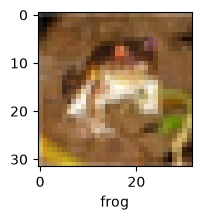

In [12]:
plot_sample(X_train, y_train, 0)

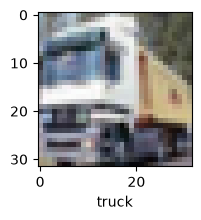

In [13]:
plot_sample(X_train, y_train, 1)

In [14]:
X_train = X_train/255.0
y_train = y_train/255.0

now lets build a ann

In [15]:
ann = models.Sequential([
    keras.Input(shape=(32,32,3)),
    layers.Flatten(),
    layers.Dense(3000, activation='relu'),
    layers.Dense(1000, activation='relu'),
    layers.Dense(10, activation='softmax')
])

ann.compile(optimizer='SGD',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
)

ann.fit(X_train, y_train, epochs=5)

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 40s 25ms/step - accuracy: 0.0999 - loss: 0.0031
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.1000 - loss: 3.0966e-04
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.1000 - loss: 1.9785e-04
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 84s 54ms/step - accuracy: 0.1000 - loss: 1.4822e-04
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 73s 47ms/step - accuracy: 0.1000 - loss: 1.1934e-04


In [16]:
ann.evaluate(X_test, y_test)

290/313 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0996 - loss: 5147.1050

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.1000 - loss: 5141.2534


[5141.25341796875, 0.10000000149011612]

In [17]:
from sklearn.metrics import confusion_matrix , classification_report
import numpy as np
y_pred = ann.predict(X_test)
y_pred_classes = [np.argmax(element) for element in y_pred]

print("Classification Report: \n", classification_report(y_test, y_pred_classes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Classification Report: 
               precision    recall  f1-score   support

           0       0.10      1.00      0.18      1000
           1       0.00      0.00      0.00      1000
           2       0.00      0.00      0.00      1000
           3       0.00      0.00      0.00      1000
           4       0.00      0.00      0.00      1000
           5       0.00      0.00      0.00      1000
           6       0.00      0.00      0.00      1000
           7       0.00      0.00      0.00      1000
           8       0.00      0.00      0.00      1000
           9       0.00      0.00      0.00      1000

    accuracy                           0.10     10000
   macro avg       0.01      0.10      0.02     10000
weighted avg       0.01      0.10      0.02     10000



d:\deep_learning_course\dl_venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\deep_learning_course\dl_venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\deep_learning_course\dl_venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Now let us build a convolutional neural network to train our images

In [18]:
cnn = models.Sequential([
    keras.Input(shape=(32, 32, 3)),                          # Explicit Input Layer (32x32 RGB image)
    
    layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

cnn.fit(X_train, y_train, epochs=10)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.1000 - loss: 0.0047
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.1000 - loss: 2.3632e-08
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 52s 33ms/step - accuracy: 0.1000 - loss: 1.5082e-08
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 52s 33ms/step - accuracy: 0.1000 - loss: 6.1337e-09
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 33ms/step - accuracy: 0.1000 - loss: 1.9383e-09
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.1000 - loss: 9.2028e-10
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.1000 - loss: 4.6253e-10
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 51s 33ms/step - accuracy: 0.1000 - loss: 2.0504e-10
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 101s 45ms/step - accuracy: 0.1000 - loss: 1.0967e-10
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 54s 34ms/step - accuracy: 0.1000 - loss: 6.9141e-11


In [19]:
cnn.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.1000 - loss: 18225.1387


[18225.138671875, 0.10000000149011612]

In [21]:
y_pred = cnn.predict(X_test)
y_pred[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


array([[1.0000000e+00, 9.7197783e-37, 0.0000000e+00, 4.5349000e-37,
        0.0000000e+00, 0.0000000e+00, 1.5441619e-33, 7.1025501e-36,
        7.7736538e-36, 3.4275048e-34],
       [1.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 5.3523307e-38, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.0000000e+00, 8.3669702e-35, 0.0000000e+00, 3.2747290e-35,
        3.5604620e-37, 0.0000000e+00, 8.5976450e-32, 4.8984870e-34,
        4.9165712e-34, 2.3318539e-32]], dtype=float32)

In [22]:
y_classes = [np.argmax(element) for element in y_pred]
y_classes[:5]

[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]

In [23]:
y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)

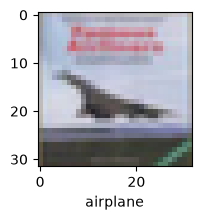

In [24]:
plot_sample(X_test, y_test,3)

In [25]:
classes[y_classes[3]]

'airplane'

In [26]:
classes[y_classes[3]]

'airplane'

dont know why we didnt see any improvement in the accuracy of the CNN model compared to the ANN model. It could be due to several factors such as the architecture of the CNN, the number of epochs, or the learning rate. Further tuning and experimentation with different architectures and hyperparameters may be necessary to achieve better performance.

but as we leared how to code cnn, thats enough to understand here. and here are some more clear information about how does cnn work.

### 1. Input $\rightarrow$ Output Flow at Every Single Stage

Using a grayscale `28 × 28 × 1` image (like MNIST) with your `32` $\rightarrow$ `64` filter architecture, here is the exact **Input $\rightarrow$ Operation $\rightarrow$ Output** chain from start to finish:
| Stage / Block | What Goes IN (Input) | What Happens Inside | What Comes OUT (Output) |
|---|---|---|---|
| **Input Layer** | **1 raw grayscale image**<br>Shape: `(28, 28, 1)` | Holds the raw pixel brightness grid (`28 × 28` pixels, `1` channel). | `(28, 28, 1)` |
| **Block 1 (Hidden Layer 1)**<br>`Conv2D(32, 3×3)` + `MaxPool(2×2)` | `(28, 28, 1)` | **1. `Conv2D(32)`:** 32 separate `3×3` filters scan the image, creating **32 feature maps** of size `26×26` (`(26, 26, 32)`).<br><br>**2. `MaxPool(2×2)`:** Takes the maximum value of each `2×2` box on every map independently, shrinking `26×26` → `13×13`. | **32 concentrated feature maps**<br>Shape: `(13, 13, 32)` |
| **Block 2 (Hidden Layer 2)**<br>`Conv2D(64, 3×3)` + `MaxPool(2×2)` | **All 32 feature maps stacked together**<br>Shape: `(13, 13, 32)` | **1. `Conv2D(64)`:** 64 3D filters (each sized `3×3×32`) slide through the entire stack of 32 maps simultaneously, combining simple edges into complex shapes to create **64 new feature maps** of size `11×11` (`(11, 11, 64)`).<br><br>**2. `MaxPool(2×2)`:** Shrinks each of those 64 maps from `11×11` → `5×5`. | **64 concentrated feature maps**<br>Shape: `(5, 5, 64)` |
| **Bridge**<br>`Flatten()` | **64 feature maps**<br>Shape: `(5, 5, 64)` | Unrolls all `64` separate `5×5` grids into one single flat 1D row of numbers ($5 \times 5 \times 64 = 1,600$ numbers). | **1,600 flat features**<br>Shape: `(1600,)` |
| **Classification Head**<br>`Dense(64)` → `Dense(10)` | **1,600 flat features**<br>Shape: `(1600,)` | Standard ANN layers weigh those 1,600 high-level visual clues (`Dense(64)`) and compute probabilities for each class (`Dense(10, softmax)`). | **10 class probabilities**<br>Shape: `(10,)`<br>Example: `99%` chance it's digit `6`. |

**Key takeaway on Hidden Layer 2's input:** The second hidden block does **not** take 64 features as input—it takes the **32 feature maps (`13×13×32`)** from Block 1 as its input, and produces **64 feature maps (`5×5×64`)** as its output. Those 64 feature maps then get unrolled (`Flatten`) into **1,600 individual numbers** before entering the `Dense` layers.

---

### 2. What Is Padding (`padding='valid'` vs. `padding='same'`)?

Padding adds a temporary border of zeros (0s) around the outer edges of an image before a convolutional filter slides across it.

Notice in the table above how every `Conv2D(3×3)` layer shaved 2 pixels off the height and width (`28×28` $\rightarrow$ `26×26`, and `13×13` $\rightarrow$ `11×11`). That happens because of two problems when a `3×3` filter slides across an image without padding:

1. **The Image Shrinks Too Fast:** If you stack 10 `Conv2D` layers on a `28×28` image, the image shrinks by 2 pixels every layer until it disappears completely (`0×0`) before you even finish feature extraction.
2. **Corner & Edge Pixels Get Ignored:** A center pixel gets touched **9 times** as the `3×3` filter slides past it, whereas a corner pixel only gets touched **once**—meaning important details near the edges of an image get under-represented.

**How Padding Solves This:**
Padding simply wraps a **border of zeros (`0`s)** around the outside edge of the image before sliding the filter:

* **`padding='valid'` (Default in Keras — No Padding):**
Adds zero border. The filter only sits where it fits completely inside the image, so a `3×3` kernel shrinks a `28×28` image to **`26×26`**.
* **`padding='same'` (Zero-Padding):**
Adds a 1-pixel ring of `0`s all around the `28×28` image (making it temporarily `30×30`). When the `3×3` filter slides across it, the output feature map comes out the **exact same height and width (`28×28`)** as the input, and edge pixels get scanned just as thoroughly as center pixels.

In Keras, turning it on is just one argument:

```python
layers.Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu')

```

#### `padding='same'` Does NOT Mean "Add 1 Ring"—It Calculates the Exact Rings Needed Automatically

`padding='same'` is an instruction to Keras/PyTorch that means: **"Add however many rings of zeros are required so the output size equals the input size"** (when `strides=1`).

The formula the framework runs automatically is:


$$\text{Total Padding Needed} = K - 1$$


where $K$ is your kernel size (so $\frac{K - 1}{2}$ rings of zeros on each side):

* **If `kernel_size=(3, 3)`:** $3 - 1 = 2$ total pixels $\rightarrow$ adds **1 ring** of zeros on top, bottom, left, and right.
* **If `kernel_size=(5, 5)`:** $5 - 1 = 4$ total pixels $\rightarrow$ automatically adds **2 rings** of zeros on every side so the `5×5` kernel can center itself right on the corner pixel without shrinking the image!
* **If `kernel_size=(7, 7)`:** $7 - 1 = 6$ total pixels $\rightarrow$ automatically adds **3 rings** of zeros on every side.

#### Do People Actually Use Kernels Larger Than `3×3`?

Yes—especially in the **very first layer** of classic and modern vision networks when processing high-resolution images (like `224×224` photos):

* **ResNet / AlexNet / ConvNeXt:** Often use a **`7×7`** kernel in the very first layer (`Conv2D(64, kernel_size=(7, 7), strides=2, padding='same')`) to quickly grab broad patterns across large images, and then switch to **`3×3`** kernels for every remaining layer in the network.
* **Custom Explicit Padding:** In PyTorch (`nn.Conv2d(..., padding=2)`) or Keras (`layers.ZeroPadding2D(padding=(2, 2))`), you can even pass an exact integer if you want custom padding that isn't `'valid'` (`0`) or `'same'`.